# 投资与现金流关系

本节借助公司金融中经典的“投资-现金流关系”问题，综合练习数据整理、变量构造、数据清洗和面板回归。公司金融理论只作必要介绍，重点放在数据处理和实证操作。

在公司金融研究中，一个常见判断是：如果外部融资充分、融资摩擦很小，企业投资主要应由投资机会决定；如果企业投资对内部资金状况特别敏感，则可能说明企业难以顺利从外部获得资金。换句话说，投资-现金流敏感性常被用作讨论融资约束的一条实证线索。

本案例围绕三个问题展开：

- 内部资金（经营现金流）越多的公司，投资强度是否更高？
- 在控制杠杆率、公司规模、公司固定效应和年份固定效应之后，这种“投资-现金流敏感性”是否仍然存在？
- 这个结果能否作为企业可能面临融资约束的证据之一？

要回答这些问题，我们至少需要构造以下几个核心变量：

1. 被解释变量：**投资强度**  
   - 用资本支出除以滞后一期总资产，刻画相对于公司规模的投资支出。
2. 主要解释变量：**现金流强度**  
   - 用（净利润 + 折旧摊销）除以滞后一期总资产，作为经营现金流的近似指标。
3. 控制变量：**杠杆率**和**公司规模**，均取上一年末（期初）的值  
   - 杠杆率用总负债除以总资产；  
   - 公司规模用总资产的自然对数。

基于这些变量，我们在后面的实证部分将使用如下基准回归模型：

$$
\text{Invest}_{i,t}= \alpha + \beta\, \text{CF}_{i,t} + \gamma\, \text{Lev}_{i,t-1} + \delta \ln(\text{TA}_{i,t-1}) + \mu_i + \lambda_t + \varepsilon_{i,t}
$$

其中：

- $\text{Invest}_{i,t}$：公司 $i$ 在年份 $t$ 的投资强度（资本支出除以滞后一期总资产）；
- $\text{CF}_{i,t}$：公司 $i$ 在年份 $t$ 的现金流强度（净利润 + 折旧摊销，除以滞后一期总资产）；
- $\text{Lev}_{i,t-1}$：上一年末的杠杆率（总负债除以总资产）；
- $\ln(\text{TA}_{i,t-1})$：上一年末的公司规模（总资产取自然对数）；
- $\mu_i$：公司固定效应；
- $\lambda_t$：年份固定效应；
- $\varepsilon_{i,t}$：误差项。

这里还读入了托宾 Q 数据。托宾 Q 常被用来代理投资机会，但为了先把主线讲清楚，本节正文的基准模型暂时不加入托宾 Q；课后作业会要求同学把它加入模型，观察现金流强度系数是否发生变化。

**数据来源：** CSMAR（国泰安）数据库。这里已经预先对数据进行了简化，可以直接从以下链接下载（讲义默认把数据放在 `data` 文件夹下）：

1. [财务信息.xlsx](data/财务信息.xlsx)
2. [相对价值.xlsx](data/相对价值.xlsx)
3. [折旧摊销.xlsx](data/折旧摊销.xlsx)
4. [上市公司基本信息.xlsx](data/上市公司基本信息.xlsx)

**需要的包和模块：** 这里使用 `pyfixest` 来进行固定效应回归。如果你尚未安装这个包，或者导入的时候出错，可以在 Notebook 中创建一个 Python 单元格，并在其中执行以下代码，即可从清华大学的软件源镜像中安装这个包：

`
!pip install -i https://pypi.tuna.tsinghua.edu.cn/simple pyfixest
`

注意：

1. 开头有个感叹号。
2. 执行一次，等待完成后即安装成功。测试能否 import，如果成功，则可以删除上述安装代码。

接下来的内容包括：

1. **构造数据**：读入原始数据表，按公司代码和会计年度合并，并复核合并结果；
2. **变量构造与样本筛选**：构造投资强度、现金流强度等变量，按上市公司研究的常见做法筛选样本，再处理缺失值和极端值；
3. **初步检查与可视化**：查看关键变量的分布和变量之间的简单关系；
4. **建模**：用面板回归刻画投资强度与现金流强度之间的关系，并讨论其含义。

## 本节涉及的知识

本节结合投资–现金流的实证案例，主要练习以下几个方面：

- Python 基础：在 Jupyter / Quarto 中使用 `pandas` 和 `numpy` 处理表格数据，借助 `matplotlib` 和 `seaborn` 完成简单绘图；
- 数据处理：多表合并、合并结果复核、构造滞后变量和比率变量、上市公司样本筛选（B 股、金融业、ST、新上市公司、资不抵债）、对数变换、处理缺失值与无穷值，以及对极端值进行缩尾（winsorization）；
- 计量经济学：面板数据的基本形式、控制变量的时点选择、用 `pyfixest` 估计公司固定效应和年份固定效应回归、整理规范的回归结果表，以及如何给出系数的经济解释。

In [1]:
# | code-fold: true
# 导入包并设置绘图主题、色板、字体和输出格式。
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyfixest as pf

okabe_ito = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#999999"]
sns.set_theme(
    style="ticks",  # 使用带刻度、少装饰的主题
    context="notebook",  # 使用适合 notebook 阅读的字号
)
sns.set_palette(okabe_ito)  # 使用色盲友好色板
plt.rcParams["font.sans-serif"] = ["Hiragino Sans GB", "Microsoft YaHei", "WenQuanYi Micro Hei"]  # 支持中文
plt.rcParams["axes.unicode_minus"] = False  # 正常显示负号
%config InlineBackend.figure_formats = ["svg"]  # 使用 SVG 格式


## 构造数据

在正式建模之前，需要先明确本案例依赖哪些原始数据表，以及它们各自包含的关键信息，后续会将这些表整理为按“公司–年份”排列的面板数据。

本例中主要使用四类数据：

- 财务信息：总资产、总负债、净利润、资本支出等；
- 相对价值指标：托宾Q值，用于刻画投资机会；
- 折旧和摊销：用于构造现金流强度；
- 上市公司基本信息：股票简称、行业、首次上市日期和上市状态，用于筛选样本。

这些数据均取自上市公司年度合并报表。

### 读取数据

接下来用 `pandas` 从本地 Excel 文件中依次读入这四类数据，并统一股票代码的格式，方便后续按照“股票代码 + 会计年度”进行合并。

接下来的几段代码依次把四张原始 Excel 表读入内存，本单元首先读取包含总资产、总负债、净利润、资本支出等指标的财务信息表，作为后续构造投资和现金流变量的基础。

- 用 `read_excel` 读取 `财务信息.xlsx`；
- 将股票代码按字符串类型导入，保证后续合并时代码格式一致；
- 查看尾部几行，检查数据是否正确读取。

In [2]:
# 读取财务信息表：包含总资产、总负债、净利润、资本支出等基础财务指标。
# read_excel 会把 Excel 文件读成一个 DataFrame（类似带表头的电子表格）。
# converters 参数把“股票代码”这一列强制读成字符串，避免像 000001 这样的代码被当成整数而丢掉前导 0。
df_fin = pd.read_excel('data/财务信息.xlsx', converters={'股票代码': str})

# 用 tail() 看看表格最后几行，确认数据是否成功读入以及列名是否正确。
df_fin.tail()


,股票代码,会计年度,总资产,总负债,净利润,营业收入,资本支出
76259,920992,2020,5.122577e+08,3.336364e+08,42591653.33,3.722132e+08,6934736.35
76260,920992,2021,5.198337e+08,2.780717e+08,67493509.40,4.652855e+08,20420360.97
76261,920992,2022,8.071261e+08,2.059728e+08,52586940.63,4.064891e+08,17328709.42
76262,920992,2023,7.328239e+08,1.313039e+08,16126507.82,3.027857e+08,7168707.21
76263,920992,2024,7.452764e+08,1.335353e+08,18087029.57,2.957733e+08,4677833.96


这一段代码读取包含托宾Q值的相对价值表，为后续扩展分析提供投资机会的衡量指标。

- 从 `相对价值.xlsx` 中读取数据；
- 同样把股票代码作为字符串处理；
- 简单查看尾部数据，确认读入无误。

In [3]:
# 读取相对价值表：主要包含托宾 Q 值等用于刻画投资机会的指标。
# 同样把股票代码读成字符串类型，方便后续按代码合并。
df_q = pd.read_excel('data/相对价值.xlsx', converters={'股票代码': str})

# 查看尾部几行，检查数据结构和列名。
df_q.tail()


,股票代码,会计年度,托宾Q值A
76704,920985,2025,1.231074
76705,920992,2022,1.136582
76706,920992,2023,1.250554
76707,920992,2024,1.275728
76708,920992,2025,1.563001


这一段代码读取折旧和摊销信息，用于在现金流强度中加入折旧项，使现金流指标更加接近经营现金流。

- 从 `折旧摊销.xlsx` 中读取数据；
- 股票代码保持为字符串类型；
- 查看尾部几行，确认数据结构。

In [4]:
# 读取折旧和摊销信息：用于在现金流中加入折旧项，使现金流指标更接近经营现金流。
# 股票代码依然保持为字符串类型。
df_dep = pd.read_excel('data/折旧摊销.xlsx', converters={'股票代码': str})

# 查看尾部几行，确认读入无误。
df_dep.tail()


,股票代码,会计年度,折旧摊销
94273,920992,2021,8616184.59
94274,920992,2022,10633218.60
94275,920992,2023,12777364.33
94276,920992,2024,13703451.55
94277,920992,2025,NaN


这一段代码读取上市公司基本信息表。它按“股票代码 + 会计年度”记录每家公司每年的基本情况，后面筛选样本时要用到其中几列：

- `行业代码`：中国上市公司协会行业分类，门类字母 `J` 表示金融业；
- `首次上市日期`：用于判断公司上市是否满 1 年；
- `上市状态`：取值包括“正常上市”“ST”“\*ST”“暂停上市”等，是公司发布当年年报时的股票状态。

In [5]:
# 读取上市公司基本信息表：包含行业代码、首次上市日期和上市状态等信息。
# 股票代码同样读成字符串类型。
df_info = pd.read_excel('data/上市公司基本信息.xlsx', converters={'股票代码': str})

# 查看尾部几行，确认读入无误。
df_info.tail()

,股票代码,会计年度,股票简称,行业代码,行业名称,首次上市日期,上市状态
74348,920992,2021,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
74349,920992,2022,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
74350,920992,2023,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
74351,920992,2024,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
74352,920992,2025,中科美菱,C35,专用设备制造业,2022-10-18,正常上市


### 数据整合

读入原始表之后，需要按照公司和年份把不同来源的信息合并在一起，形成一张包含投资、现金流、杠杆率等变量的宽表，作为后续变量构造和清洗的基础。


在读入四张表之后，需要按照公司和年份把它们合并在一起，得到一张包含全部变量的宽表。

- 以 `股票代码` 和 `会计年度` 为键进行合并；
- 财务信息和折旧摊销是构造核心变量必需的，用内连接（`inner`）只保留两张表都有记录的观测；
- 托宾 Q 只在课后作业中使用，基本信息只用于筛选样本，这两张表用左连接（`left`）合并，匹配不上的观测先保留，取值记为缺失。这样不会因为托宾 Q 缺失而误删基准回归需要的观测。

In [6]:
# 将四张表按“股票代码 + 会计年度”这对键合并，得到一张宽表。
# 财务信息与折旧摊销用 how='inner'：只保留两张表中都存在的公司-年份组合。
# 托宾 Q 和基本信息用 how='left'：以左边的表为准，匹配不上的观测保留下来，对应列为 NaN。
df_all = pd.merge(
    df_fin,
    df_dep,
    on=['股票代码', '会计年度'],
    how='inner'
).merge(
    df_q,
    on=['股票代码', '会计年度'],
    how='left'
).merge(
    df_info,
    on=['股票代码', '会计年度'],
    how='left'
)

# 查看合并后数据的尾部，了解行数和列名是否符合预期。
df_all.tail()

,股票代码,会计年度,总资产,总负债,净利润,营业收入,资本支出,折旧摊销,托宾Q值A,股票简称,行业代码,行业名称,首次上市日期,上市状态
75306,920992,2020,5.122577e+08,3.336364e+08,42591653.33,3.722132e+08,6934736.35,10285215.80,NaN,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75307,920992,2021,5.198337e+08,2.780717e+08,67493509.40,4.652855e+08,20420360.97,8616184.59,NaN,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75308,920992,2022,8.071261e+08,2.059728e+08,52586940.63,4.064891e+08,17328709.42,10633218.60,1.136582,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75309,920992,2023,7.328239e+08,1.313039e+08,16126507.82,3.027857e+08,7168707.21,12777364.33,1.250554,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75310,920992,2024,7.452764e+08,1.335353e+08,18087029.57,2.957733e+08,4677833.96,13703451.55,1.275728,中科美菱,C35,专用设备制造业,2022-10-18,正常上市


为了方便按时间顺序构造滞后变量，本段代码先复制一份合并后的数据，并按公司和年份排序。

- 用 `copy` 生成工作用的数据框；
- 按 `股票代码`、`会计年度` 递增排序；
- 粗略查看排序后的数据。

In [7]:
# 复制一份合并后的数据，作为后面所有处理的起点，避免直接修改原始数据。
df = df_all.copy()

# 为了按时间顺序构造滞后变量，需要先按公司和会计年度排序。
# sort_values 会按照给定的列从小到大排序。
df = df.sort_values(['股票代码', '会计年度'])

# 查看排序后的尾部几行，检查排序是否合理。
df.tail()


,股票代码,会计年度,总资产,总负债,净利润,营业收入,资本支出,折旧摊销,托宾Q值A,股票简称,行业代码,行业名称,首次上市日期,上市状态
75306,920992,2020,5.122577e+08,3.336364e+08,42591653.33,3.722132e+08,6934736.35,10285215.80,NaN,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75307,920992,2021,5.198337e+08,2.780717e+08,67493509.40,4.652855e+08,20420360.97,8616184.59,NaN,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75308,920992,2022,8.071261e+08,2.059728e+08,52586940.63,4.064891e+08,17328709.42,10633218.60,1.136582,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75309,920992,2023,7.328239e+08,1.313039e+08,16126507.82,3.027857e+08,7168707.21,12777364.33,1.250554,中科美菱,C35,专用设备制造业,2022-10-18,正常上市
75310,920992,2024,7.452764e+08,1.335353e+08,18087029.57,2.957733e+08,4677833.96,13703451.55,1.275728,中科美菱,C35,专用设备制造业,2022-10-18,正常上市


## 数据复核

合并之后、构造变量之前，先对数据做一轮复核。复核只负责发现问题、了解问题的规模，具体怎么处理放在后面的变量构造和样本筛选中。本节检查四件事：

1. 主键是否唯一：每家公司每年是否只有一条记录；
2. 合并是否完整：左连接的表有多少观测没有匹配上；
3. 年份是否连续：构造滞后变量时，“上一行”是否就是“上一年”；
4. 取值是否合理：总资产、资本支出、负债等是否出现违背会计常识的取值。

### 主键唯一性

在面板数据的设定下，我们希望“每家公司、每一年”只有一条记录，也就是 (股票代码, 会计年度) 这一对键在数据中是唯一的。如果出现同一家公司同一年有多条观测，往往说明在原始数据或合并过程中存在问题，需要回头核查数据来源或处理步骤。

In [8]:
# 检查 (股票代码, 会计年度) 这一对键是否有重复值。
# 在理想的面板数据中，每家公司每一年应该只有一条记录。
dup_mask = df.duplicated(subset=['股票代码', '会计年度'], keep=False)
dup_count = dup_mask.sum()

print(f"重复的公司-年份组合数量: {dup_count}")

# 如果发现有重复，可以把这些行单独筛出来，回头检查原始数据或合并逻辑。
if dup_count > 0:
    df_duplicates = df.loc[dup_mask].sort_values(['股票代码', '会计年度'])
    df_duplicates.head()


重复的公司-年份组合数量: 0


### 合并匹配情况

左连接不会删除观测，但匹配不上的观测在右表的列上全部是缺失值。下面统计托宾 Q 和基本信息各有多少观测没有匹配上，并按年份看基本信息未匹配的观测集中在哪些年份。

In [9]:
# 统计左连接后，托宾 Q 和基本信息分别有多少观测没有匹配上。
# isna() 判断是否缺失，sum() 统计 True 的个数。
print(f"托宾 Q 未匹配的观测数: {df['托宾Q值A'].isna().sum()}")
print(f"基本信息未匹配的观测数: {df['上市状态'].isna().sum()}")

# 按会计年度统计基本信息未匹配的观测数，查看它们集中在哪些年份。
df.loc[df['上市状态'].isna(), '会计年度'].value_counts().sort_index().head(15)

托宾 Q 未匹配的观测数: 5115
基本信息未匹配的观测数: 6481


会计年度
1991       7
1992       3
1993      10
1994     228
1995     361
1996     389
1997     605
1998     929
1999    1027
2000      91
2001      92
2002      96
2003      91
2004      90
2005      90
Name: count, dtype: int64

可以看到，基本信息未匹配的观测大部分在 2000 年以前，因为本例使用的基本信息表从 2000 年开始。2000 年以后也有少量未匹配的观测，主要是 B 股（基本信息表以 A 股代码为主）和北交所公司上市以前的年份。这些观测缺少行业和上市状态，无法判断是否应当剔除，后面会在样本筛选的第一步删除。

### 年份连续性

后面构造滞后一期总资产时，会使用 `groupby` 加 `shift(1)` 取同一家公司的“上一行”。只有当公司的年份连续时，“上一行”才等于“上一年”。如果某家公司缺了某一年的数据（例如 2010 年之后直接是 2012 年），2012 年取到的“滞后值”实际上是 2010 年的总资产。

下面计算每家公司相邻两条记录的年份差，统计年份差不等于 1 的情况。

In [10]:
# 在每家公司内部，计算本行年份与上一行年份之差。
# diff() 的作用是“本行减上一行”；每家公司的第一行没有上一行，结果为 NaN。
df['年份差'] = df.groupby('股票代码')['会计年度'].diff()

# 统计年份差大于 1 的观测数，即年份出现断档的情况。
print(f"年份断档的观测数: {(df['年份差'] > 1).sum()}")

# 查看几条断档记录。
df.loc[df['年份差'] > 1, ['股票代码', '会计年度', '年份差']].head()

年份断档的观测数: 9


,股票代码,会计年度,年份差
4599,000563,1995,2.0
52018,600601,1994,2.0
52050,600602,1994,3.0
53481,600652,1994,3.0
53510,600653,1994,3.0


断档的观测数量不多，但处理方法必须正确：构造滞后变量时，只在年份差恰好等于 1 时才使用上一行的数值，其余情况记为缺失。

### 取值合理性

最后检查几项基本的会计关系：总资产应当为正，资本支出通常不为负，总负债一般不超过总资产。不满足这些条件的观测不一定是数据错误（例如资不抵债的公司确实存在），但需要知道它们的数量，再决定如何处理。

In [11]:
# 统计几类不符合常见会计关系的观测数。
value_check = pd.Series(
    {
        "总资产不为正": (df["总资产"] <= 0).sum(),
        "资本支出为负": (df["资本支出"] < 0).sum(),
        "总负债大于总资产": (df["总负债"] > df["总资产"]).sum(),
    }
)

value_check

总资产不为正        3
资本支出为负        8
总负债大于总资产    843
dtype: int64

其中“总负债大于总资产”的观测有几百条，也就是资不抵债的公司。它们的杠杆率大于 1，有的甚至达到几百，会严重影响回归结果。这类观测在下一节按照常见做法剔除；总资产不为正的观测在数据清洗中删除；资本支出为负的观测很少，暂时保留。

## 创建所需变量

有了合并后的财务数据，可以根据经济含义构造投资强度、现金流强度、杠杆率和公司规模等变量。投资强度和现金流强度要用上一年末的总资产标准化，杠杆率和规模在回归中也使用上一年末的值，因此还需要构造这几个变量的滞后一期。

先构造当期的杠杆率和公司规模。

- 使用总负债除以总资产得到 `杠杆率`，衡量公司负债融资的程度；
- 对总资产取自然对数得到 `ln_总资产`，只对总资产为正的观测取对数。

In [12]:
# 构造杠杆率：总负债 / 总资产。
df['杠杆率'] = df['总负债'] / df['总资产']

# 构造规模变量：总资产的自然对数 ln(TotalAssets)。
# 为了避免对 0 或负数取对数，只对总资产为正的观测取 log。
df.loc[df['总资产'] > 0, 'ln_总资产'] = np.log(df.loc[df['总资产'] > 0, '总资产'])

接下来构造滞后一期的总资产、杠杆率和规模。

- 按公司分组，用 `shift(1)` 取同一家公司上一行的数值；
- 根据数据复核中计算的 `年份差`，年份不连续时把滞后值设为缺失；
- 三个变量的处理方法相同，用一个循环完成，结果分别存入 `总资产_lag`、`杠杆率_lag` 和 `ln_总资产_lag`。

为什么控制变量要用上一年末的值？当年的杠杆率和规模本身会受到当年投资的影响：企业借钱投资，当年的负债和总资产都会上升。如果用当期值，控制变量和被解释变量同时变化，系数的含义就不清楚了。用期初值表示“企业在做当年投资决策时的状况”，也和被解释变量用期初总资产标准化的思路一致，这是投资–现金流文献中的常见做法。

In [13]:
# 需要构造滞后一期的变量。
lag_cols = ['总资产', '杠杆率', 'ln_总资产']

for col in lag_cols:
    # 先按股票代码分组，在每个公司内部用 shift(1) 取上一行的数值。
    df[col + '_lag'] = df.groupby('股票代码')[col].shift(1)
    # 只有年份差等于 1 时，上一行才是上一年；其他情况把滞后值设为缺失。
    df.loc[df['年份差'] != 1, col + '_lag'] = np.nan

# 抽取部分公司近几年的滞后变量，简单检查结果是否合理。
df[['股票代码', '会计年度', '总资产', '总资产_lag', '杠杆率', '杠杆率_lag']].tail(10)

,股票代码,会计年度,总资产,总资产_lag,杠杆率,杠杆率_lag
75301,920992,2015,1.340434e+08,NaN,0.246740,NaN
75302,920992,2016,1.747784e+08,1.340434e+08,0.354072,0.246740
75303,920992,2017,2.675815e+08,1.747784e+08,0.529185,0.354072
75304,920992,2018,2.762977e+08,2.675815e+08,0.502978,0.529185
75305,920992,2019,3.036931e+08,2.762977e+08,0.509082,0.502978
75306,920992,2020,5.122577e+08,3.036931e+08,0.651306,0.509082
75307,920992,2021,5.198337e+08,5.122577e+08,0.534924,0.651306
75308,920992,2022,8.071261e+08,5.198337e+08,0.255193,0.534924
75309,920992,2023,7.328239e+08,8.071261e+08,0.179175,0.255193
75310,920992,2024,7.452764e+08,7.328239e+08,0.179176,0.179175


有了滞后总资产之后，就可以构造投资强度和现金流强度。

- 使用资本支出除以滞后总资产得到 `投资强度`；
- 使用（净利润 + 折旧摊销）除以滞后总资产得到 `现金流强度`。

In [14]:
# 构造投资强度：资本支出 / 滞后总资产。
# 这样可以将投资规模标准化，便于不同规模公司之间比较。
df['投资强度'] = df['资本支出'] / df['总资产_lag']

# 构造现金流强度：近似的经营现金流 / 滞后总资产。
# 这里用（净利润 + 折旧摊销）作为经营现金流的近似。
df['现金流强度'] = (df['净利润'] + df['折旧摊销']) / df['总资产_lag']

# 查看几个关键变量的尾部，感受一下大致数值范围。
df[['股票代码', '会计年度', '投资强度', '现金流强度', '杠杆率_lag', 'ln_总资产_lag']].tail(10)

,股票代码,会计年度,投资强度,现金流强度,杠杆率_lag,ln_总资产_lag
75301,920992,2015,NaN,NaN,NaN,NaN
75302,920992,2016,0.306915,0.068383,0.246740,18.713674
75303,920992,2017,0.222403,0.091179,0.354072,18.979029
75304,920992,2018,0.068494,0.080883,0.529185,19.404935
75305,920992,2019,0.058542,0.077569,0.502978,19.436989
75306,920992,2020,0.022835,0.174113,0.509082,19.531528
75307,920992,2021,0.039863,0.148577,0.651306,20.054338
75308,920992,2022,0.033335,0.121616,0.534924,20.069019
75309,920992,2023,0.008882,0.035811,0.255193,20.508990
75310,920992,2024,0.006383,0.043381,0.179175,20.412416


## 上市公司数据的常见处理

使用中国上市公司数据做实证研究时，通常要先按照一些惯例筛选样本。这些惯例在各类论文中反复出现，原因是某些公司或年份的财务数据和一般公司不可比：

1. **剔除未匹配基本信息的观测**：缺少行业和上市状态，无法执行后面的筛选；
2. **剔除 B 股**：B 股代码以 200、201（深市）和 900（沪市）开头。很多 B 股公司同时发行 A 股，保留 B 股会让同一家公司在样本中出现两次；
3. **剔除金融业**：银行、证券、保险等金融企业的资产负债结构和一般企业差别很大，例如银行的负债率普遍在 90% 以上，资本支出的含义也不同；
4. **剔除 ST、\*ST 等非正常上市状态的观测**：这些公司经营或财务状况异常，常有亏损、重组和资产处置，财务指标波动大；
5. **剔除上市不满 1 年的观测**：公司上市当年会募集大量资金，总资产、现金和投资都会大幅跳升，和正常经营年份不可比；
6. **剔除资不抵债的观测**：总负债大于总资产时，杠杆率大于 1，所有者权益为负。

不同论文的具体标准会有差别，例如是否保留北交所公司、ST 按年报时点还是按年末判断、“上市不满 1 年”是否包含上市当年等。写论文时应在样本说明中把采用的标准交代清楚。本例保留北交所公司，ST 按上市状态判断，并剔除上市当年及以前的观测。

这些筛选都是简单的条件过滤，可以放在一个单元格里依次完成。几点说明：

- `str[:3]` 取股票代码的前三位，`isin` 判断是否属于给定的代码段，`~` 表示取反；
- 行业代码的第一个字母是门类，`J` 表示金融业。行业按年份记录，这里按每一年的行业判断；
- `pd.to_datetime(...).dt.year` 取出上市年份。只保留会计年度大于上市年份的观测，这样既删除了上市当年，也删除了上市以前的年份（数据库有时会收录公司上市前几年的财务数据）；
- 筛选完成后，和筛选前比较一下观测数和公司数，确认样本没有缩小到无法回归的程度。

In [15]:
# 先把包含所有派生变量的 df 复制一份，之后的筛选、清洗和缩尾都在 df_clean 上进行。
df_clean = df.copy()

df_clean = df_clean[df_clean['上市状态'].notna()]  # 删除未匹配基本信息的观测
df_clean = df_clean[~df_clean['股票代码'].str[:3].isin(['200', '201', '900'])]  # 剔除 B 股
df_clean = df_clean[~df_clean['行业代码'].str.startswith('J')]  # 剔除金融业
df_clean = df_clean[df_clean['上市状态'] == '正常上市']  # 剔除 ST、*ST、暂停上市等
df_clean = df_clean[df_clean['会计年度'] > pd.to_datetime(df_clean['首次上市日期']).dt.year]  # 剔除上市不满 1 年
df_clean = df_clean[df_clean['总负债'] <= df_clean['总资产']]  # 剔除资不抵债

# 比较筛选前后的观测数和公司数。
print(f"筛选前：{len(df)} 条观测，{df['股票代码'].nunique()} 家公司")
print(f"筛选后：{len(df_clean)} 条观测，{df_clean['股票代码'].nunique()} 家公司")

筛选前：75311 条观测，5821 家公司
筛选后：57748 条观测，5468 家公司


## 数据清洗

完成样本筛选之后，还需要对数据做一些基本清洗，保证关键变量的取值合理、不会因为极端值或异常值影响回归结果。

常见的清洗步骤包括：

1. 处理无穷大值；
2. 删除总资产或滞后总资产不合理（如非正数）的观测；
3. 删除回归变量存在缺失值的观测；
4. 对少数极端值进行缩尾 winsor，把最大和最小的一部分观测缩到给定的临界值。

数据中可能存在无穷大或无穷小的取值，会影响统计描述和回归结果，因此需要先将这些值统一视为缺失。

- 将 `inf` 和 `-inf` 替换为缺失值 `NaN`；
- 为后续的过滤和删除缺失观测做准备。

In [16]:
# 有些变量在计算过程中可能出现无穷大（inf）或无穷小（-inf），
# 比如分母接近 0 的情况。为了后续处理方便，先把这些值统一视为缺失值 NaN。
df_clean = df_clean.replace([np.inf, -np.inf], np.nan)


为了保证比率指标和对数变量的含义合理，本段代码把总资产或滞后总资产不为正的观测剔除掉。

- 要求 `总资产` 大于 0；
- 要求 `总资产_lag` 大于 0；
- 得到一组经济含义更清晰的观测样本。

In [17]:
# 为了保证比率和对数变量的经济含义合理，
# 我们只保留总资产和滞后总资产都为正的观测。
# 滞后总资产为 NaN 时比较结果为 False，所以这一步也会删除没有上一年数据的观测。
df_clean = df_clean[(df_clean['总资产'] > 0) & (df_clean['总资产_lag'] > 0)]

在处理完无穷值和不合理观测之后，删除回归变量仍然存在缺失值的观测，得到用于回归的干净样本。

- 用 `dropna` 的 `subset` 参数只检查回归用到的变量；
- 如果不指定 `subset`，任何一列有缺失都会被删除。例如托宾 Q 缺失的观测也会被删掉，而基准回归并不使用托宾 Q，这会无故缩小样本。

In [18]:
# 基准回归用到的变量。
reg_vars = ['投资强度', '现金流强度', '杠杆率_lag', 'ln_总资产_lag']

# dropna(subset=...) 只要求这几列不缺失，其他列（如托宾 Q）缺失的观测仍然保留。
df_clean = df_clean.dropna(subset=reg_vars)

# 粗略查看几个关键变量，确认不再有缺失。
df_clean[['股票代码', '会计年度'] + reg_vars].tail()

,股票代码,会计年度,投资强度,现金流强度,杠杆率_lag,ln_总资产_lag
75290,920982,2024,0.108469,0.546793,0.335583,21.084109
75299,920985,2023,0.087440,0.062198,0.665894,22.065367
75300,920985,2024,0.182422,0.074091,0.644271,22.044792
75309,920992,2023,0.008882,0.035811,0.255193,20.508990
75310,920992,2024,0.006383,0.043381,0.179175,20.412416


## 样本和变量说明

完成筛选和清洗之后，先看一下最终样本的基本情况。实证分析通常需要交代样本包含多少条公司-年份观测、覆盖哪些年份、涉及多少家公司。这样读者才能判断样本范围和后续回归结果的基础。

In [19]:
# 汇总清洗后样本的公司数量、年份范围和观测数量
sample_summary = pd.Series(
    {
        "公司数量": df_clean["股票代码"].nunique(),
        "观测数量": len(df_clean),
        "起始年份": int(df_clean["会计年度"].min()),
        "结束年份": int(df_clean["会计年度"].max()),
    }
)

sample_summary

公司数量     5467
观测数量    57574
起始年份     2000
结束年份     2024
dtype: int64

下面把本案例使用的主要变量整理成一张说明表。变量说明表的作用是把“变量名、定义、经济含义”集中放在一起，方便后面阅读描述性统计和回归结果。

In [20]:
# | code-fold: true
# 整理主要变量的定义和经济含义
variable_info = pd.DataFrame(
    {
        "变量": ["投资强度", "现金流强度", "杠杆率_lag", "ln_总资产_lag", "托宾Q值A"],
        "定义": [
            "资本支出 / 滞后一期总资产",
            "（净利润 + 折旧摊销）/ 滞后一期总资产",
            "上一年末总负债 / 上一年末总资产",
            "上一年末总资产的自然对数",
            "相对价值指标，作为投资机会的代理变量",
        ],
        "经济含义": [
            "衡量企业相对于规模的投资支出",
            "衡量企业内部资金的充裕程度",
            "衡量企业期初的负债融资程度",
            "控制企业期初的规模差异",
            "衡量企业面对的投资机会，本节作业中使用",
        ],
    }
)

variable_info

,变量,定义,经济含义
0,投资强度,资本支出 / 滞后一期总资产,衡量企业相对于规模的投资支出
1,现金流强度,（净利润 + 折旧摊销）/ 滞后一期总资产,衡量企业内部资金的充裕程度
2,杠杆率_lag,上一年末总负债 / 上一年末总资产,衡量企业期初的负债融资程度
3,ln_总资产_lag,上一年末总资产的自然对数,控制企业期初的规模差异
4,托宾Q值A,相对价值指标，作为投资机会的代理变量,衡量企业面对的投资机会，本节作业中使用


在建模之前，先对核心变量做一次描述性统计，了解它们的大致分布和尺度。

- 选取回归用到的四个变量 `reg_vars`；
- 计算均值、标准差、分位数等基本统计量。

In [21]:
# 对核心变量做一次描述性统计，了解它们的大致分布和尺度。
# describe() 会给出均值、标准差、分位数等信息，
# .T 表示转置，方便以“变量为行”的形式阅读结果。
df_clean[reg_vars].describe().round(4).T


,count,mean,std,min,25%,50%,75%,max
投资强度,57574.0,0.0675,0.5846,-0.1194,0.0160,0.0396,0.0815,121.7143
现金流强度,57574.0,0.0918,3.1508,-2.7799,0.0338,0.0639,0.1020,607.7302
杠杆率_lag,57574.0,0.4239,0.2214,-0.1947,0.2631,0.4189,0.5745,13.6291
ln_总资产_lag,57574.0,21.9762,1.3315,13.0760,21.0377,21.7784,22.6922,28.6969


为了减少少数极端值对回归结果的影响，本段代码对几个连续变量做 1%–99% 的缩尾处理，并在处理后再次查看描述性统计。

- 对回归用到的四个变量 `reg_vars` 缩尾；
- 规模变量缩尾的是对数值 `ln_总资产_lag`，不再另外对总资产缩尾。如果同时缩尾总资产和它的对数，两者各自按自己的分位数截断，结果会不一致；
- 使用 `winsorize` 对两端各 1% 的观测进行裁剪；
- 再次输出描述性统计，观察极端值被压缩后的变化。

In [22]:
# 从 scipy 导入 winsorize 函数，用于对变量进行缩尾（winsorization）。
from scipy.stats.mstats import winsorize

# 对每个变量做 1%–99% 的缩尾处理：
# limits=[0.01, 0.01] 表示把最小的 1% 和最大的 1% 的观测值
# 压到对应分位数上，从而减少极端值对回归结果的影响。
for col in reg_vars:
    df_clean[col] = winsorize(df_clean[col], limits=[0.01, 0.01])

# 缩尾之后再看一次描述性统计，观察极端值被压缩后的变化。
df_clean[reg_vars].describe().round(4).T

,count,mean,std,min,25%,50%,75%,max
投资强度,57574.0,0.0611,0.0663,0.0002,0.0160,0.0396,0.0815,0.3524
现金流强度,57574.0,0.0673,0.0727,-0.1792,0.0338,0.0639,0.1020,0.3073
杠杆率_lag,57574.0,0.4227,0.2011,0.0523,0.2631,0.4189,0.5745,0.8702
ln_总资产_lag,57574.0,21.9733,1.2951,19.6161,21.0377,21.7784,22.6922,26.0637


在回归之前，再看一下核心变量之间的相关系数矩阵。它可以初步展示投资强度与现金流强度的关系，也可以检查解释变量之间是否高度相关。如果解释变量之间的相关系数非常高（例如超过 0.8），回归系数会变得不稳定。

In [23]:
# corr() 计算两两变量之间的皮尔逊相关系数。
df_clean[reg_vars].corr().round(3)

,投资强度,现金流强度,杠杆率_lag,ln_总资产_lag
投资强度,1.000,0.324,-0.089,-0.077
现金流强度,0.324,1.000,-0.236,-0.008
杠杆率_lag,-0.089,-0.236,1.000,0.423
ln_总资产_lag,-0.077,-0.008,0.423,1.000


下面通过直方图粗略观察总资产的分布，判断样本中公司规模的集中程度和极端值情况。这里的总资产没有缩尾，可以看到原始数据的偏态。

这里使用前面 seaborn 章节中的整理方式：先创建 `fig` 和 `ax`，再用 seaborn 作图，最后统一调整标题、坐标轴、边框和留白。

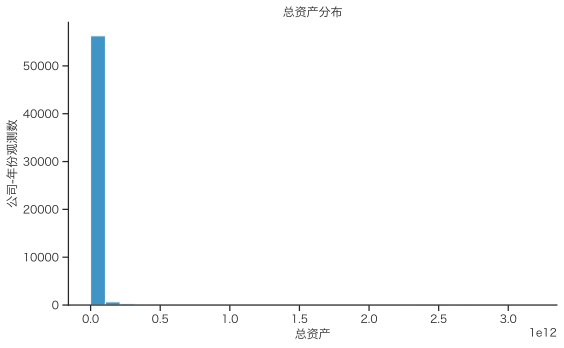

In [24]:
# 绘制总资产的直方图，并整理标题、坐标轴和边框
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='总资产',
    bins=30,  # 设置直方图分组数量
    color=okabe_ito[0],
    ax=ax,
)

ax.set_title('总资产分布')
ax.set_xlabel('总资产')
ax.set_ylabel('公司-年份观测数')
sns.despine(ax=ax)  # 去掉上边框和右边框
fig.tight_layout()  # 自动调整留白
plt.show()

同样地，对取对数后的总资产绘制直方图。和原始总资产相比，对数总资产通常更集中，更便于观察公司规模的大致分布。

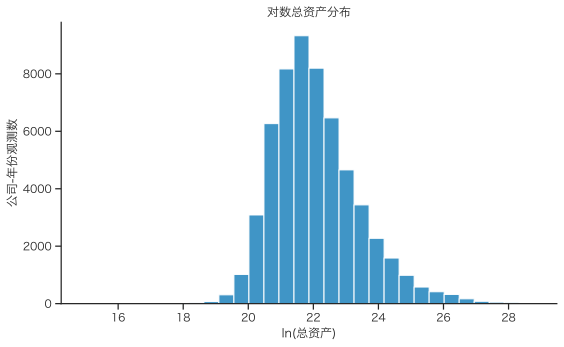

In [25]:
# 绘制对数总资产的直方图，并整理图形细节
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='ln_总资产',
    bins=30,  # 设置直方图分组数量
    color=okabe_ito[0],
    ax=ax,
)

ax.set_title('对数总资产分布')
ax.set_xlabel('ln(总资产)')
ax.set_ylabel('公司-年份观测数')
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

为了直观感受投资强度与现金流强度之间的关系，本段代码绘制散点图并叠加一条简单的拟合线。

- 以现金流强度为横轴、投资强度为纵轴；
- 使用较透明的小点表示观测；
- 用同一色板中的强调色显示线性拟合结果。

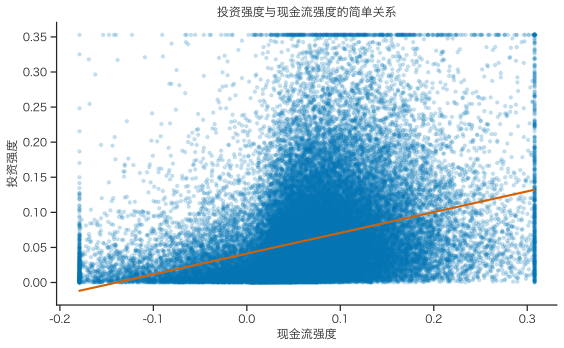

In [26]:
# 绘制投资强度与现金流强度关系的散点图，并叠加一条简单的拟合线。
fig, ax = plt.subplots(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x='现金流强度',
    y='投资强度',
    scatter_kws={'alpha': 0.2, 's': 10, 'rasterized': True},  # alpha 控制透明度，s 控制点的大小；rasterized 把散点画成位图，避免 SVG 文件过大
    line_kws={'color': okabe_ito[3], 'linewidth': 2},  # 使用色板中的强调色画拟合线
    ax=ax,
)

ax.set_title('投资强度与现金流强度的简单关系')
ax.set_xlabel('现金流强度')
ax.set_ylabel('投资强度')
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 基准回归

在这一部分，我们基于前面构造的变量，估计如下基准回归模型：

$$
\text{Invest}_{i,t}
= \alpha
+ \beta\, \text{CF}_{i,t}
+ \gamma\, \text{Lev}_{i,t-1}
+ \delta \ln(\text{TA}_{i,t-1})
+ \mu_i + \lambda_t + \varepsilon_{i,t}.
$$

在本例中：

- 被解释变量 `投资强度` 是资本支出除以滞后一期总资产；
- 主要解释变量 `现金流强度` 是（净利润 + 折旧摊销）除以滞后一期总资产；
- 控制变量是上一年末的杠杆率 `杠杆率_lag` 和规模 `ln_总资产_lag`；
- 模型中加入公司固定效应 $\mu_i$ 和年份固定效应 $\lambda_t$，标准误按公司聚类。

下面依次估计三个模型：不含固定效应的单变量回归、加入固定效应的单变量回归，以及加入控制变量的基准回归。这里的基准模型暂时不加入托宾 Q，托宾 Q 作为投资机会的代理变量放在课后作业中扩展。

### 使用 pyfixest 估计固定效应模型

前面线性回归一章用 `linearmodels` 的 `PanelOLS` 介绍了固定效应。本节改用 `pyfixest`，原因有三点：

- 写法简洁：数据不需要设置多重索引，也不需要手动添加常数项，用一个公式就能写清楚模型；
- 固定效应更灵活：`PanelOLS` 最多只能加入两组固定效应，`pyfixest` 可以加入任意多组，例如后面会用到的行业 × 年份固定效应；
- 和常用工具一致：它的写法与 R 的 `fixest`、Stata 的 `reghdfe` 基本相同，实证论文中常用，结果表也可以直接整理成论文格式。

`pyfixest` 用一个字符串公式描述模型，基本格式是：

```
被解释变量 ~ 解释变量1 + 解释变量2 | 固定效应1 + 固定效应2
```

- `~` 左边是被解释变量，右边是解释变量，多个解释变量用 `+` 连接；
- 截距项自动加入，不需要手动添加；
- `|` 右边是固定效应，写数据中表示公司、年份的列名即可。没有固定效应时省略 `|` 及其右边的部分；
- 变量名直接使用数据框的列名，中文列名也可以；
- 估计函数是 `pf.feols(公式, data=数据, vcov=标准误类型)`。`vcov={'CRV1': '股票代码'}` 表示标准误按公司聚类。

例如，本节的基准模型写作：

```
投资强度 ~ 现金流强度 + 杠杆率_lag + ln_总资产_lag | 股票代码 + 会计年度
```

如果尚未安装 `pyfixest`，可以执行 `!pip install -i https://pypi.tuna.tsinghua.edu.cn/simple pyfixest`。

下面的代码估计三个模型，标准误都按公司聚类，便于在同一张表中比较。

- 模型 (1)：只包含现金流强度，不含固定效应；
- 模型 (2)：只包含现金流强度，加入公司和年份固定效应；
- 模型 (3)：加入滞后一期的杠杆率和规模，即基准模型。

运行时会出现一条提示：`singleton fixed effect(s) dropped`。它指的是在样本中只出现一次的公司。加入公司固定效应后，这类观测的投资强度完全被它自己的固定效应解释，不提供任何组内信息，却会让标准误偏小，因此 `pyfixest` 默认把它们删除。所以模型 (2)、(3) 的观测数比模型 (1) 少一些。

In [27]:
# 模型 (1)：单变量回归，不含固定效应。
m1 = pf.feols('投资强度 ~ 现金流强度', data=df_clean, vcov={'CRV1': '股票代码'})

# 模型 (2)：单变量回归，加入公司固定效应和年份固定效应。
m2 = pf.feols('投资强度 ~ 现金流强度 | 股票代码 + 会计年度', data=df_clean, vcov={'CRV1': '股票代码'})

# 模型 (3)：基准回归，加入滞后一期的杠杆率和规模。
m3 = pf.feols(
    '投资强度 ~ 现金流强度 + 杠杆率_lag + ln_总资产_lag | 股票代码 + 会计年度',
    data=df_clean,
    vcov={'CRV1': '股票代码'},
)

/opt/anaconda3/envs/econ/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 330 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/opt/anaconda3/envs/econ/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 330 singleton fixed effect(s) dropped from the model.
  warnings.warn(


每个模型都可以用 `summary()` 查看详细结果，包括系数、标准误、t 值、p 值和置信区间。下面查看基准模型 (3)。

In [28]:
m3.summary()

###

Estimation:  OLS
Dep. var.: 投资强度, Fixed effects: 股票代码 + 会计年度
sample: None = all
Inference:  CRV1
Observations:  57244

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| 现金流强度    |      0.218 |        0.007 |    30.061 |      0.000 |  0.204 |   0.232 |
| 杠杆率_lag    |     -0.028 |        0.003 |    -8.295 |      0.000 | -0.035 |  -0.021 |
| ln_总资产_lag |     -0.006 |        0.001 |    -6.457 |      0.000 | -0.007 |  -0.004 |
---
RMSE: 0.05 R2: 0.439 R2 Within: 0.072 


论文中通常把几个模型放在同一张表中比较。`pf.etable()` 可以把多个模型整理成一张回归表：

- `signif_code=[0.01, 0.05, 0.1]`：按经济学论文的惯例，`***`、`**`、`*` 分别表示在 1%、5%、10% 水平上显著；
- `labels`：把变量名替换为表格中显示的名称；
- `show_fe=False` 和 `custom_model_stats`：不使用默认的固定效应行，而是自己写出“是否包含公司固定效应、年份固定效应”和“标准误聚类层级”这几行。论文的回归表都应当交代这些信息；
- `notes`：表格下方的注释。

系数下方括号内的数字是标准误。

In [29]:
pf.etable(
    [m1, m2, m3],
    signif_code=[0.01, 0.05, 0.1],
    labels={'Intercept': '常数项'},
    show_fe=False,
    custom_model_stats={
        '公司固定效应': ['否', '是', '是'],
        '年份固定效应': ['否', '是', '是'],
        '标准误聚类': ['公司', '公司', '公司'],
    },
    notes='括号内为按公司聚类的标准误。***、**、* 分别表示在 1%、5%、10% 水平上显著。',
)

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef             现金流强度  0.296*** <br> (0.007)   
1              coef           杠杆率_lag                          
2              coef        ln_总资产_lag                          
3              coef               常数项  0.041*** <br> (0.001)   
4             stats            公司固定效应                      否   
5             stats            年份固定效应                      否   
6             stats             标准误聚类                     公司   
7             stats      Observations                 57,574   
8             stats                R²                  0.105   

                       1                       2  
0  0.235*** <br> (0.007)   0.218*** <br> (0.007)  
1                         -0.028*** <br> (0.003)  
2                         -0.006*** <br> (0.001)  
3                                                 
4                      是                       是  
5                      是                       是  
6                     公司                      公司  
7                 57,244                  57,244  
8                  0.434                   0.439  , _body=<great_tables._gt_data.Body object at 0x70436d34d0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label='(3)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x704371b4d0>, _spanners=Spanners([SpannerInfo(spanner_id='投资强度', spanner_level=1, spanner_label='投资强度', spanner_units=None, spanner_pattern=None, vars=['0', '1', '2'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x70436d38c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x704371ae90>, _source_notes=['括号内为按公司聚类的标准误。***、**、* 分别表示在 1%、5%、10% 水平上显著。'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x70436d3a10>, _formats=[], _substitutions=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', val

### 回归结果的解读

从上面的回归表可以看到：

- 不含固定效应的模型 (1) 中，现金流强度的系数约为 0.30，在 1% 水平上显著；
- 加入公司和年份固定效应后，模型 (2) 中现金流强度的系数下降到约 0.24，仍然在 1% 水平上显著。说明部分相关关系来自公司之间不随时间变化的差异和年份共同冲击，但控制这些因素之后，关系依然存在；
- 在基准模型 (3) 中加入期初杠杆率和规模后，现金流强度的系数约为 0.22，t 值约为 30，变化不大。说明这一关系并不是由杠杆或规模差异驱动的。

控制变量的系数也有合理的经济含义：

- 期初杠杆率的系数为负。期初负债越高的企业，进一步举债的空间越小，投资也越少；
- 期初规模的系数为负。在控制公司固定效应后，这个系数反映的是同一家公司在规模变大以后，投资强度有所下降，与企业成长后进入成熟期、投资放缓的规律一致。

关于 $R^2$，需要注意：模型 (2)、(3) 中的 $R^2$ 约为 0.43–0.44，其中大部分来自固定效应本身，也就是公司之间投资强度的长期差异。`m3.summary()` 中的 `R2 Within` 只衡量解释变量对公司内部投资变化的解释力，约为 0.07。投资决策受到许多难以观测的因素影响，组内 $R^2$ 较低在这类研究中很常见。

从经济含义上，可以有以下直观理解：

- 基准模型的系数约为 0.22 意味着，在其他条件不变的情况下，如果一家公司的现金流强度提高 0.10（例如从 0.05 上升到 0.15），其投资强度平均会提高约 0.022。样本中投资强度的中位数约为 0.04，这个变化幅度并不小，说明内部资金状况对投资有较明显的影响；
- 在控制公司固定效应、年份固定效应以及期初杠杆率和规模之后，这种“投资-现金流敏感性”仍然显著存在。这个结果与企业存在一定融资约束的解释相一致：当内部资金较为紧张时，投资支出可能会被压缩；
- 但投资-现金流敏感性本身不能单独证明融资约束。更严谨的分析还需要控制投资机会，例如加入托宾 Q，也可以进一步做规模分组、行业分组或其他稳健性检查。

在课后作业中，你可以在此基础上加入托宾 Q 和规模分组，考察在不同投资机会、不同公司规模下，这种投资-现金流敏感性是否会发生改变。

### 识别限制

固定效应回归已经比简单相关分析更进一步。公司固定效应可以控制公司层面不随时间变化的特征，年份固定效应可以控制所有公司共同面对的年度冲击。

但这并不等于已经完成严格的因果识别。当前模型仍可能受到随时间变化的遗漏变量影响，例如行业景气度、管理层变化、融资环境变化等；也可能存在反向因果，例如企业准备扩大投资时，同时提前安排融资和现金持有。因此，本节的结果更适合作为投资-现金流关系的实证描述和融资约束的初步线索，而不是单独作为严格因果证明。

## 课后作业：扩展投资–现金流关系分析

本小节的代码已经构造了投资强度、现金流强度、杠杆率、规模等变量，并完成了基础的面板回归。请在此基础上，独立完成以下两个扩展练习，并整理为一个可运行的 notebook：

1. 将托宾Q加入控制变量

- 数据中已经合并了 `托宾Q值A`，请将其作为投资机会的代理变量加入到基础回归模型中。
- 要求：
  - 投资机会应当在投资决策之前观察到，因此使用滞后一期的托宾 Q。在构造滞后变量的单元格中，把 `托宾Q值A` 加入 `lag_cols`，即可得到 `托宾Q值A_lag`。注意滞后变量要在样本筛选之前、在 `df` 上构造：`df_clean` 已经删除了部分观测，在它上面使用 `shift(1)` 取到的“上一行”可能不是上一年。
  - 在此基础上构造包含 `托宾Q值A_lag` 的回归数据集（注意处理缺失值和极端值，可以与其他连续变量采用相同的 winsor 处理方式）。
  - 在公司固定效应 + 年份固定效应的设定下，估计以下模型：
    - 投资强度 ~ 现金流强度 + 杠杆率_lag + ln_总资产_lag + 托宾Q值A_lag
  - 比较加入托宾Q前后，现金流强度系数的大小和显著性是否发生变化，并用简短文字解释你的观察。

2. 按规模分组的异质性检验

- 利用期初规模 `ln_总资产_lag` 作为公司规模的度量，按照样本内中位数将公司划分为“规模较小”（Small）和“规模较大”（Big）两组。
- 要求：
  - 给出分组方法的具体实现（例如：基于某一年整体样本的中位数，或者基于全样本的中位数），并在代码中清晰标注。
  - 分别在 Small 组和 Big 组样本上，估计与课堂中相同设定的回归模型（至少包括：
    - 投资强度 ~ 现金流强度 + 杠杆率_lag + ln_总资产_lag
    - 公司固定效应 + 年份固定效应）。
  - 对比两组样本中现金流强度系数的大小和显著性，讨论投资–现金流敏感性是否存在“规模异质性”。

提示：

- 建议在每一步回归前，先输出关键变量的描述性统计和相关性矩阵，检查数据是否合理。
- 在汇总回归结果时，可以使用 `pf.etable` 函数，或者自行整理为表格，方便横向对比不同模型和不同样本组的估计结果。
